# Phase 0 — Setup and linear algebra warm-up

**Purpose.** Check that your Python tools work, then practise the six linear
algebra ideas that the trading lab is built on. Each idea is shown first as
numbers, then as a picture.

| Idea | Where the lab uses it |
|---|---|
| Vector | one list of trade results, one list of weights |
| Matrix | the Monte Carlo grid: rows are paths, columns are trades |
| Matrix product `A @ B` | portfolio return, mixing random numbers |
| Covariance matrix `Σ` | how slots move together (your Section 1c check) |
| Quadratic form `wᵀΣw` | portfolio risk (your `sqrt((1+ρ)/2)` rule) |
| Cholesky `Σ = LLᵀ` and eigenvectors | simulate correlated slots, find hidden themes |

**How to use.** Run every cell from top to bottom (`Kernel ▸ Restart & Run All`).
Then do the exercises at the end.

First install the libraries, once, from a terminal in this folder:

```
pip install -r requirements.txt
```

In [1]:
# Step 0 - check the tools. Every line should print a version number.
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy

import lab_style as ls
ls.use_lab_style()

print("Python     ", sys.version.split()[0])
print("NumPy      ", np.__version__)
print("pandas     ", pd.__version__)
print("matplotlib ", matplotlib.__version__)
print("SciPy      ", scipy.__version__)

Python      3.13.18
NumPy       2.5.3
pandas      3.0.5
matplotlib  3.11.2
SciPy       1.18.1


## 1. Vector — a list of numbers with a direction

Five trades, in R: four losers at −1R and one winner at +8R.
The **sum** is the total result. The **mean** is the expectancy of this sample.

In [2]:
trades_R = np.array([-1.0, -1.0, 8.0, -1.0, -1.0])
print("trades (R)  :", trades_R)
print("total       :", trades_R.sum(), "R")
print("mean        :", trades_R.mean(), "R per trade")

# The dot product multiplies matching entries and adds them up.
# Here: probability of each outcome times its size = expectancy.
prob = np.array([0.77, 0.23])
size = np.array([-1.0, 8.0])
print("expectancy  :", prob @ size, "R   (0.77 x -1  +  0.23 x 8)")

trades (R)  : [-1. -1.  8. -1. -1.]
total       : 4.0 R
mean        : 0.8 R per trade
expectancy  : 1.07 R   (0.77 x -1  +  0.23 x 8)


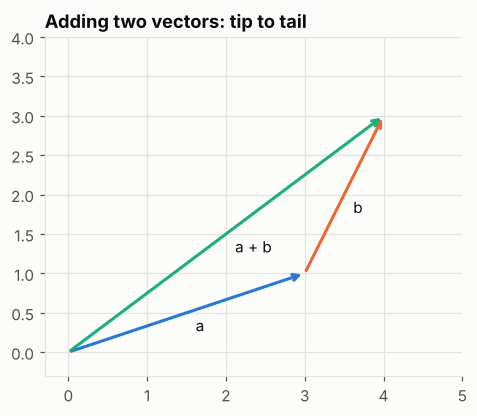

In [3]:
# Picture: a vector is an arrow. Adding vectors puts the arrows tip to tail.
a = np.array([3.0, 1.0])
b = np.array([1.0, 2.0])

fig, ax = plt.subplots(figsize=(5, 4))
for start, vec, color, name in [((0, 0), a, ls.BLUE, "a"),
                                (a, b, ls.ORANGE, "b"),
                                ((0, 0), a + b, ls.AQUA, "a + b")]:
    ax.annotate("", xy=(start[0] + vec[0], start[1] + vec[1]), xytext=start,
                arrowprops=dict(arrowstyle="->", color=color, lw=2))
    mid = (start[0] + vec[0] / 2, start[1] + vec[1] / 2)
    ax.annotate(name, mid, textcoords="offset points", xytext=(6, -12),
                color=ls.TEXT)
ax.set_xlim(-0.3, 5); ax.set_ylim(-0.3, 4); ax.set_aspect("equal")
ax.set_title("Adding two vectors: tip to tail")
plt.show()

## 2. Matrix — a table of numbers

The Monte Carlo grid in Phase 1 is a matrix. **Each row is one possible
future. Each column is one trade.** Below: 4 futures, 6 trades each.

In [4]:
rng = np.random.default_rng(3)
is_win = rng.random((4, 6)) < 0.23        # True where the trade wins
R = np.where(is_win, 8.0, -1.0)           # +8R for a win, -1R for a loss

print("shape (rows, columns):", R.shape)
print(R)
print("\ntotal R of each future (sum along the columns, axis=1):", R.sum(axis=1))
print("mean R of each trade number (down the rows, axis=0)    :", R.mean(axis=0))

shape (rows, columns): (4, 6)
[[ 8. -1. -1. -1.  8. -1.]
 [-1.  8. -1.  8. -1. -1.]
 [-1. -1. -1. -1. -1. -1.]
 [-1. -1.  8. -1. -1. -1.]]

total R of each future (sum along the columns, axis=1): [12. 12. -6.  3.]
mean R of each trade number (down the rows, axis=0)    : [ 1.25  1.25  1.25  1.25  1.25 -1.  ]


## 3. Matrix product `@` and transpose `.T`

`A @ B` combines rows of `A` with columns of `B`. Inner sizes must match:
`(m, n) @ (n, k)` gives `(m, k)`. `.T` swaps rows and columns.

Example: three days of returns for two stocks, and a weight for each stock.
`returns @ w` gives the portfolio return of each day.

In [5]:
returns = np.array([[0.02, -0.01],
                    [-0.03, 0.01],
                    [0.01, 0.04]])      # 3 days x 2 stocks
w = np.array([0.5, 0.5])                # half the money in each stock

print("returns shape:", returns.shape, " weights shape:", w.shape)
print("portfolio return per day:", returns @ w)
print("\ntranspose (2 stocks x 3 days):\n", returns.T)

returns shape: (3, 2)  weights shape: (2,)
portfolio return per day: [ 0.005 -0.01   0.025]

transpose (2 stocks x 3 days):
 [[ 0.02 -0.03  0.01]
 [-0.01  0.01  0.04]]


## 4. Covariance matrix `Σ` and the quadratic form `wᵀΣw`

The covariance matrix holds every pair's "moves together" number.
Portfolio variance is `wᵀΣw`. Its square root is portfolio volatility.

Your notebook rule says two equal slots with correlation `ρ` swing
`sqrt((1+ρ)/2)` as much as one double-size slot. Check it with matrices.

In [6]:
s = 1.0                                  # volatility of one slot's result
print(" rho   w'Σw route   your formula")
for rho in [0.0, 0.3, 0.7, 1.0]:
    Sigma = np.array([[s**2, rho * s**2],
                      [rho * s**2, s**2]])
    w_two = np.array([1.0, 1.0])         # one unit of risk in each slot
    w_one = np.array([2.0, 0.0])         # two units of risk in one slot
    vol_two = np.sqrt(w_two @ Sigma @ w_two)
    vol_one = np.sqrt(w_one @ Sigma @ w_one)
    print(f" {rho:.1f}     {vol_two / vol_one:.3f}        {np.sqrt((1 + rho) / 2):.3f}")

 rho   w'Σw route   your formula
 0.0     0.707        0.707
 0.3     0.806        0.806
 0.7     0.922        0.922
 1.0     1.000        1.000


Both columns match. Your rule is the 2×2 case of `wᵀΣw`. With matrices the
same line of code works for 2 slots or 200 stocks.

## 5. Cholesky — make random numbers move together

A computer gives independent random numbers. Markets do not. The Cholesky
factor `L` (where `Σ = LLᵀ`) fixes that: `z @ L.T` turns independent numbers
`z` into numbers with the correlation you asked for.

In [7]:
rho = 0.6
corr = np.array([[1.0, rho], [rho, 1.0]])
L = np.linalg.cholesky(corr)
print("L =\n", L.round(3))
print("\nL @ L.T gives back the correlation matrix:\n", (L @ L.T).round(3))

z = rng.standard_normal((2000, 2))       # independent
x = z @ L.T                              # correlated
print("\ncorrelation before:", np.corrcoef(z.T)[0, 1].round(2))
print("correlation after :", np.corrcoef(x.T)[0, 1].round(2), "(target 0.6)")

L =
 [[1.  0. ]
 [0.6 0.8]]

L @ L.T gives back the correlation matrix:
 [[1.  0.6]
 [0.6 1. ]]



correlation before: 0.02
correlation after : 0.61 (target 0.6)


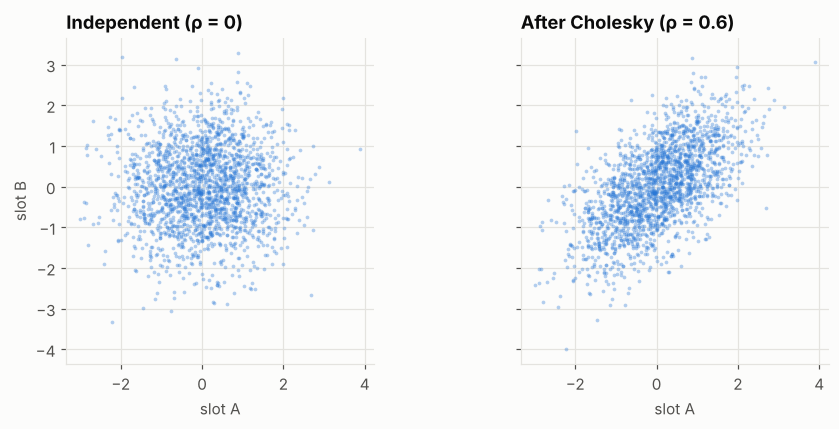

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, data, title in [(axes[0], z, "Independent (ρ = 0)"),
                        (axes[1], x, "After Cholesky (ρ = 0.6)")]:
    ax.scatter(data[:, 0], data[:, 1], s=6, color=ls.BLUE, alpha=0.35,
               linewidths=0)
    ax.set_title(title); ax.set_xlabel("slot A"); ax.set_aspect("equal")
axes[0].set_ylabel("slot B")
plt.tight_layout(); plt.show()

Left: a round cloud, the slots ignore each other. Right: a tilted cloud,
when slot A is bad slot B is usually bad too. That tilt is rule B1,
"one theme is one bet", as a picture.

## 6. Eigenvectors — the main directions of the cloud

An eigenvector of `Σ` is a direction the cloud stretches along. Its
eigenvalue is how much. One large eigenvalue means one hidden theme
drives both slots. Phase 4 uses this to find themes among many stocks.

eigenvalues      : [1.64 0.39]
share of variance: [81. 19.] %


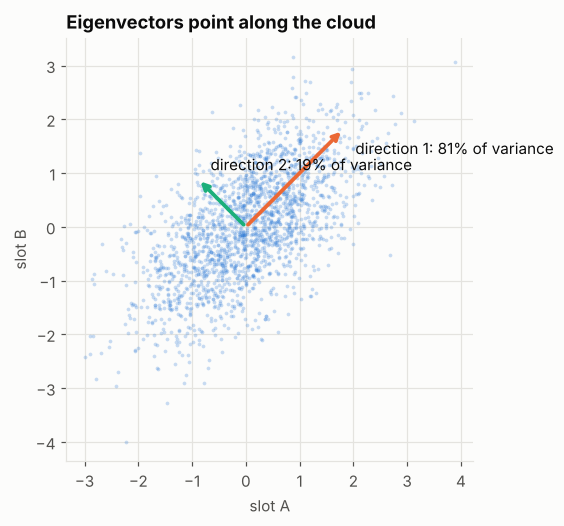

In [9]:
values, vectors = np.linalg.eigh(np.cov(x.T))
order = np.argsort(values)[::-1]
values, vectors = values[order], vectors[:, order]
share = values / values.sum()
print("eigenvalues      :", values.round(2))
print("share of variance:", (100 * share).round(0), "%")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(x[:, 0], x[:, 1], s=6, color=ls.BLUE, alpha=0.25, linewidths=0)
for i, color in enumerate([ls.ORANGE, ls.AQUA]):
    tip = vectors[:, i] * 2 * np.sqrt(values[i])
    ax.annotate("", xy=tip, xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=color, lw=2.5))
    ax.annotate(f"direction {i + 1}: {100 * share[i]:.0f}% of variance", tip,
                textcoords="offset points", xytext=(8, -16 if i == 0 else 6),
                color=ls.TEXT)
ax.set_aspect("equal"); ax.set_xlabel("slot A"); ax.set_ylabel("slot B")
ax.set_title("Eigenvectors point along the cloud")
plt.show()

## Exercises

1. In section 1, change the winner from +8R to +3R. Is the expectancy still positive?
2. In section 2, change the grid to 1,000 futures of 300 trades. What is `R.shape`?
   What is the mean of the row totals?
3. In section 4, add a third slot. Build a 3×3 `Σ` with `ρ = 0.3` everywhere and
   compare three 1-unit slots against one 3-unit slot.
4. In section 5, set `rho = 0.95`. How does the scatter change? What happens to
   the first eigenvalue share in section 6?

When these feel easy, open `01_monte_carlo_engine.ipynb`.